# Customer Churn Prediction and Retention Analytics

**Business problem.** A telecom operator loses subscribers while retention spend goes out
flat to everyone. This notebook answers four questions with one model contract: who will
churn, what is driving it, when a customer is likely to leave, and which customers are
worth paying to keep.

**Stack.** Python for the whole ML path (pandas, scikit-learn, XGBoost, LightGBM, PyTorch,
Optuna, SHAP, lifelines, Pandera, DuckDB, FastAPI, Streamlit) and R for an independent
survival cross-check (`r/survival_analysis.R`).

**How to read this notebook.** Every cell that does real work calls the same functions the
production pipeline calls (`src/features.py`, `src/dq.py`, `src/monitor.py`,
`src/external.py`). It writes no files. The last cell asserts that what it computed
matches the committed artefacts in `outputs/`, so a reader can tell whether the notebook
and the pipeline agree rather than taking that on faith.

**Data.** IBM Telco Customer Churn (7,043 rows, 21 columns) as the primary feed, plus
IBM's *Telco customer churn (11.1.3+)* six-module release as a second source. The second
release is a re-coded re-release of the same book of business, not a later period -
see `data/raw/ibm_telco_11_1_3/PROVENANCE.md` and the Drift section.

In [1]:
%matplotlib inline
import json, subprocess, sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (9, 4.5)

import features as F
import dq
import monitor
import external

RNG = 42
OUT = Path("outputs")
pd.set_option("display.width", 160)
print("pandas", pd.__version__, "| feature contract:", len(F.CAT), "categorical +", len(F.NUM), "numeric")

pandas 3.1.0 | feature contract: 16 categorical + 16 numeric


## 1. Ingestion and data quality

The CSV is read with `dtype=str, keep_default_na=False` on purpose. `TotalCharges` is the
one column with legitimate blanks - 11 rows, all `tenure = 0`, customers who have not
billed yet - and the default reader decides what a blank means instead of the pipeline.
Pandera schemas (raw and typed) plus 35 business checks produce the scorecard.

In [2]:
raw = F.load_raw("data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
raw.shape, list(raw.columns) == dq.EXPECTED_COLUMNS

((7043, 21), True)

In [3]:
for name, schema in [("telco_raw", dq.telco_raw_schema()),
                     ("telco_clean", dq.telco_clean_schema())]:
    frame = raw if name == "telco_raw" else F.coerce_numeric(raw)
    print(name, dq.validate_schema(frame, schema))

telco_raw (True, 'telco_raw passed on 7043 rows')
telco_clean (True, 'telco_clean passed on 7043 rows')


In [4]:
card = dq.run_dq_checks(raw)
print(f"DQ score {card['passed'].mean():.1%}  ({int(card['passed'].sum())}/{len(card)} checks)")
failures = card.loc[~card["passed"], ["check", "layer", "detail"]]
failures if len(failures) else "all checks green"

DQ score 100.0%  (35/35 checks)


'all checks green'

In [5]:
blanks = raw[raw["TotalCharges"].str.strip() == ""]
blanks[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20,
5218,2923-ARZLG,0,19.7,
6670,4075-WKNIU,0,73.35,


In [6]:
df = F.engineer(raw)
df["target"].mean(), df["tenure"].min(), df["tenure"].max(), df["MonthlyCharges"].max()

(np.float64(0.2653698707936959), np.int64(0), np.int64(72), np.float64(118.75))

The domain values are not incidental: they are what `dq.ALLOWED` and the FastAPI request
model validate against, so a category that is not on this list cannot reach the encoder
where `handle_unknown="ignore"` would silently zero it.

In [7]:
pd.DataFrame({"column": dq.EXPECTED_COLUMNS,
              "distinct": [raw[c].nunique() for c in dq.EXPECTED_COLUMNS],
              "levels": [sorted(raw[c].unique())[:4] for c in dq.EXPECTED_COLUMNS]}).head(21)

,column,distinct,levels
0,customerID,7043,"[0002-ORFBO, 0003-MKNFE, 0004-TLHLJ, 0011-IGKFF]"
1,gender,2,"[Female, Male]"
2,SeniorCitizen,2,"[0, 1]"
3,Partner,2,"[No, Yes]"
4,Dependents,2,"[No, Yes]"
5,tenure,73,"[0, 1, 10, 11]"
6,PhoneService,2,"[No, Yes]"
7,MultipleLines,3,"[No, No phone service, Yes]"
8,InternetService,3,"[DSL, Fiber optic, No]"
9,OnlineSecurity,3,"[No, No internet service, Yes]"


## 2. Where the churn actually is

Three structural facts drive everything downstream, and they are visible before any model
is fitted: month-to-month contracts churn at roughly three times the two-year rate, the
first twelve months are where customers are lost, and no online security or no tech
support is a stronger signal than price.

In [8]:
def churn_by(col):
    t = df.groupby(col, observed=True)["target"].agg(churners="sum", customers="size", churn_rate="mean")
    return t.sort_values("churn_rate", ascending=False).round(4)

churn_by("Contract")

,churners,customers,churn_rate
Contract,,,
Month-to-month,1655,3875,0.4271
One year,166,1473,0.1127
Two year,48,1695,0.0283


In [9]:
churn_by("tenure_band")

,churners,customers,churn_rate
tenure_band,,,
0-12,1037,2186,0.4744
13-24,294,1024,0.2871
25-48,325,1594,0.2039
49-72,213,2239,0.0951


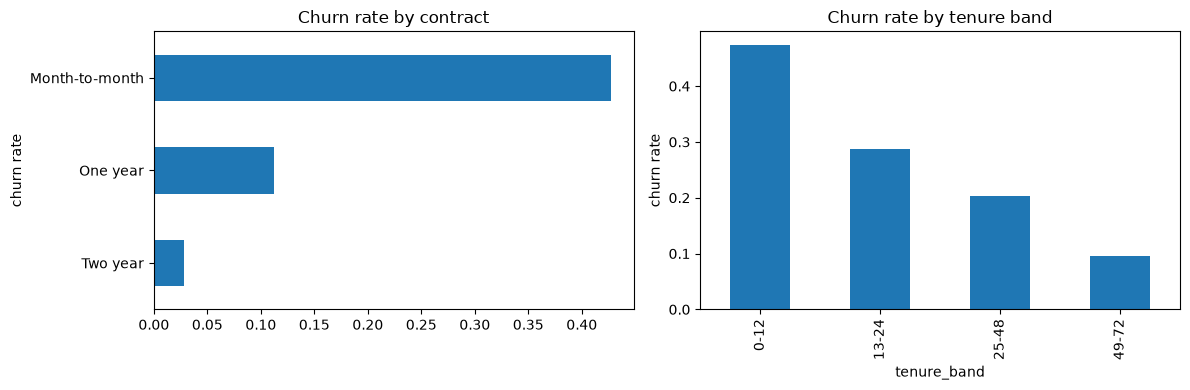

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
churn_by("Contract")[::-1].plot(kind="barh", y="churn_rate", ax=axes[0], legend=False,
                                title="Churn rate by contract")
churn_by("tenure_band").plot(kind="bar", y="churn_rate", ax=axes[1], legend=False,
                             title="Churn rate by tenure band")
for ax in axes:
    ax.set_ylabel("churn rate")
plt.tight_layout(); plt.show()

In [11]:
for col in ["PaymentMethod", "InternetService", "OnlineSecurity", "TechSupport", "SeniorCitizen"]:
    print(col); print(churn_by(col).to_string()); print()

PaymentMethod
                           churners  customers  churn_rate
PaymentMethod                                             
Electronic check               1071       2365      0.4529
Mailed check                    308       1612      0.1911
Bank transfer (automatic)       258       1544      0.1671
Credit card (automatic)         232       1522      0.1524

InternetService
                 churners  customers  churn_rate
InternetService                                 
Fiber optic          1297       3096      0.4189
DSL                   459       2421      0.1896
No                    113       1526      0.0740

OnlineSecurity
                     churners  customers  churn_rate
OnlineSecurity                                      
No                       1461       3498      0.4177
Yes                       295       2019      0.1461
No internet service       113       1526      0.0740

TechSupport
                     churners  customers  churn_rate
TechSupport            

In [12]:
from scipy.stats import chi2_contingency, mannwhitneyu

tests = []
for col in ["Contract", "PaymentMethod", "InternetService", "TechSupport", "OnlineSecurity",
            "PaperlessBilling", "MultipleLines"]:
    chi2, p, _, _ = chi2_contingency(pd.crosstab(df[col], df["target"]))
    tests.append({"test": "chi-square", "variable": col, "statistic": round(chi2, 1), "p_value": f"{p:.3e}"})
for col in ["tenure", "MonthlyCharges", "TotalCharges", "service_count"]:
    u, p = mannwhitneyu(df.loc[df["target"] == 1, col], df.loc[df["target"] == 0, col])
    tests.append({"test": "Mann-Whitney U", "variable": col, "statistic": round(u, 1), "p_value": f"{p:.3e}"})
stat_tests = pd.DataFrame(tests)
stat_tests

,test,variable,statistic,p_value
0,chi-square,Contract,1184.6,5.863e-258
1,chi-square,PaymentMethod,648.1,3.682e-140
2,chi-square,InternetService,732.3,9.572e-160
3,chi-square,TechSupport,828.2,1.443e-180
4,chi-square,OnlineSecurity,850.0,2.661e-185
5,chi-square,PaperlessBilling,258.3,4.073e-58
6,chi-square,MultipleLines,11.3,3.464e-03
7,Mann-Whitney U,tenure,2515538.0,2.420e-208
8,Mann-Whitney U,MonthlyCharges,6003125.5,3.312e-54
9,Mann-Whitney U,TotalCharges,3381224.0,5.685e-83


Every test rejects at p &lt; 0.001, which is the honest framing: with 7,043 rows association
is not the interesting part. Effect size is, and it is in the tables above.

## 3. Segmentation on a snapshot

There is no signup date, so RFM here is adapted rather than literal: **R** is the tenure
quintile (a proxy for recency, not days-since-last-activity), **F** is the count of
subscribed services, **M** is monthly charges. Stating the substitution matters more than
the score.

In [13]:
seg = df.copy()
for src, out in [("tenure", "r_score"), ("service_count", "f_score"), ("MonthlyCharges", "m_score")]:
    seg[out] = pd.qcut(seg[src], 5, labels=False, duplicates="drop") + 1
seg["rfm_total"] = seg["r_score"] + seg["f_score"] + seg["m_score"]
bands = pd.cut(seg["rfm_total"], [0, 6, 8, 10, 12, 15],
               labels=["At risk", "Mid value", "Growing", "Core", "Champions"])
seg.assign(band=bands).groupby("band", observed=True).agg(
    customers=("target", "size"), churn_rate=("target", "mean"),
    monthly_revenue=("MonthlyCharges", "sum")).round(3)

,customers,churn_rate,monthly_revenue
band,,,
At risk,2156,0.290,76494.35
Mid value,1368,0.292,76353.60
Growing,1222,0.308,88626.00
Core,924,0.258,78861.85
Champions,1373,0.167,135780.80


## 4. Modelling

`train_test_split` with `stratify=y` and a fixed seed. A time-based split is not available
on a snapshot and pretending otherwise would be the worst kind of leak, so the limitation
is recorded instead. The model input contract is `F.CAT + F.NUM`, built by
`F.build_preprocessor()` - one-hot with `handle_unknown="ignore"` plus a standard scaler.

In [14]:
from sklearn.model_selection import train_test_split

X, y = df[F.CAT + F.NUM], df["target"].values
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, df.index, test_size=0.25, random_state=RNG, stratify=y)
pre = F.build_preprocessor()
print(len(X_train), "train /", len(X_test), "test | base churn rate", round(y.mean(), 4))

5282 train / 1761 test | base churn rate 0.2654


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, brier_score_loss,
                             confusion_matrix, precision_score)
import xgboost, lightgbm
from torch_nn import TorchFeedforwardClassifier

def make_pipe(mdl):
    return Pipeline([("pre", pre), ("model", mdl)])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RNG,
                                            class_weight="balanced_subsample", n_jobs=-1),
    "XGBoost": xgboost.XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                                     subsample=0.9, colsample_bytree=0.9, eval_metric="logloss",
                                     n_jobs=-1, random_state=RNG),
    "LightGBM": lightgbm.LGBMClassifier(n_estimators=300, max_depth=-1, learning_rate=0.05,
                                         verbose=-1, random_state=RNG, class_weight="balanced"),
    "MLP (sklearn feedforward)": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=400, random_state=RNG),
    "Feedforward NN (PyTorch)": TorchFeedforwardClassifier(hidden_layer_sizes=(64, 32), dropout=0.3,
                                                           learning_rate=1e-3, max_epochs=120, patience=12,
                                                           random_state=RNG),
}

def eval_row(name, p):
    order = np.argsort(-p)
    top = order[: max(1, int(0.10 * len(p)))]
    top_recall = float(y_test[top].sum() / max(1, y_test.sum()))
    return {"model": name, "roc_auc": round(float(roc_auc_score(y_test, p)), 4),
            "pr_auc": round(float(average_precision_score(y_test, p)), 4),
            "f1_at_0.5": round(float(f1_score(y_test, (p >= 0.5).astype(int))), 4),
            "top_decile_recall": round(top_recall, 4), "top_decile_lift": round(top_recall / 0.10, 2)}

The PyTorch network is a real feedforward net, not a wrapper around sklearn's MLP:
64-32 with BatchNorm, dropout 0.3, Adam on a class-weighted BCE loss, mini-batch
training with early stopping on validation loss. It is exposed as an sklearn estimator so
it enters the same `Pipeline` and the same comparison table as everything else.

In [16]:
results, preds, pipes = [], {}, {}
for name, mdl in models.items():
    pipe = make_pipe(mdl)
    pipe.fit(X_train, y_train)
    pipes[name] = pipe
    preds[name] = pipe.predict_proba(X_test)[:, 1]
    results.append(eval_row(name, preds[name]))
    print(f"  {name}: ROC-AUC {results[-1]['roc_auc']:.4f}")

torch_epochs = pipes["Feedforward NN (PyTorch)"].named_steps["model"].n_iter_
print("PyTorch net early-stopped at epoch", torch_epochs)

  Logistic Regression: ROC-AUC 0.8493


  Random Forest: ROC-AUC 0.8282


  XGBoost: ROC-AUC 0.8365


  LightGBM: ROC-AUC 0.8334


  MLP (sklearn feedforward): ROC-AUC 0.7632


  Feedforward NN (PyTorch): ROC-AUC 0.8468
PyTorch net early-stopped at epoch 27


## 5. Optuna tuning

15 TPE trials, seeded at 42. The objective is **stratified 3-fold CV PR-AUC on the
training split only** - never test-set score, which is how tuned models quietly become
overfit to the evaluation you were supposed to keep clean.

In [17]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {"n_estimators": trial.suggest_int("n_estimators", 100, 400),
              "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.15, log=True),
              "num_leaves": trial.suggest_int("num_leaves", 15, 63),
              "min_child_samples": trial.suggest_int("min_child_samples", 10, 60),
              "subsample": trial.suggest_float("subsample", 0.7, 1.0),
              "colsample_bytree": trial.suggest_float("colsample_bytree", 0.7, 1.0)}
    pipe = make_pipe(lightgbm.LGBMClassifier(**params, verbose=-1, random_state=RNG, class_weight="balanced"))
    cv = StratifiedKFold(3, shuffle=True, random_state=RNG)
    oof = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba", n_jobs=1)[:, 1]
    return average_precision_score(y_train, oof)

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RNG))
study.optimize(objective, n_trials=15)
best_params = study.best_params
trials = (pd.DataFrame([{"trial": t.number, "pr_auc_cv": round(t.value, 5), **t.params}
                        for t in study.trials]).sort_values("pr_auc_cv", ascending=False))
print("best CV PR-AUC", round(study.best_value, 4))
trials.head(6)

best CV PR-AUC 0.654


,trial,pr_auc_cv,n_estimators,learning_rate,num_leaves,min_child_samples,subsample,colsample_bytree
12,12,0.65396,123,0.025350,19,26,0.819373,0.840200
13,13,0.65372,132,0.027216,26,23,0.753727,0.815706
14,14,0.65131,194,0.023219,26,16,0.796463,0.808831
6,6,0.64718,191,0.024350,48,32,0.736611,0.848553
5,5,0.64715,282,0.028200,18,58,0.989690,0.942519
10,10,0.64576,248,0.028345,32,34,0.748963,0.854606


In [18]:
tuned = make_pipe(lightgbm.LGBMClassifier(**best_params, verbose=-1, random_state=RNG, class_weight="balanced"))
tuned.fit(X_train, y_train)
preds["LightGBM (Optuna-tuned)"] = tuned.predict_proba(X_test)[:, 1]
pipes["LightGBM (Optuna-tuned)"] = tuned
results.append(eval_row("LightGBM (Optuna-tuned)", preds["LightGBM (Optuna-tuned)"]))

comp = pd.DataFrame(results).sort_values("pr_auc", ascending=False).reset_index(drop=True)
comp

,model,roc_auc,pr_auc,f1_at_0.5,top_decile_recall,top_decile_lift
0,Logistic Regression,0.8493,0.6625,0.6234,0.2848,2.85
1,LightGBM (Optuna-tuned),0.8472,0.6538,0.6341,0.2741,2.74
2,Feedforward NN (PyTorch),0.8468,0.6521,0.6220,0.2848,2.85
3,XGBoost,0.8365,0.6363,0.5659,0.2741,2.74
4,LightGBM,0.8334,0.6354,0.6270,0.2805,2.81
5,Random Forest,0.8282,0.6200,0.5401,0.2634,2.63
6,MLP (sklearn feedforward),0.7632,0.5068,0.5248,0.2163,2.16


Tuning LightGBM does not beat the regularised logistic regression on this dataset, and
that is reported rather than hidden. Seven model families were tried (linear, bagged,
two gradient-boosting stacks, sklearn MLP, the PyTorch network, tuned LightGBM); nothing
built from the 21 published columns clears ROC-AUC 0.85.

## 6. Calibration and thresholds

The best model by test PR-AUC is isotonic-calibrated with `CalibratedClassifierCV(cv=3)`
and that **calibrated** artefact is what scores every customer, what the batch job loads
and what the API serves. Ranking barely moves (isotonic is monotone); the probability
scale does, which is the whole reason to bother - the tier cutoffs and the value-at-risk
arithmetic are read as probabilities.

In [19]:
best_name = comp.iloc[0]["model"]
best_pipe, best_p = pipes[best_name], preds[best_name]
cal = CalibratedClassifierCV(best_pipe, method="isotonic", cv=3)
cal.fit(X_train, y_train)
p_cal = cal.predict_proba(X_test)[:, 1]

print(f"deployed model: {best_name} + isotonic calibration over 3 folds")
print(f"ROC-AUC  uncalibrated {roc_auc_score(y_test, best_p):.4f}   calibrated {roc_auc_score(y_test, p_cal):.4f}")
print(f"PR-AUC   uncalibrated {average_precision_score(y_test, best_p):.4f}   calibrated {average_precision_score(y_test, p_cal):.4f}")
print(f"Brier    uncalibrated {brier_score_loss(y_test, best_p):.5f}   calibrated {brier_score_loss(y_test, p_cal):.5f}"
      f"   base-rate-only {brier_score_loss(y_test, np.full(len(y_test), y.mean())):.5f}")
print(confusion_matrix(y_test, (p_cal >= 0.5).astype(int)))

deployed model: Logistic Regression + isotonic calibration over 3 folds
ROC-AUC  uncalibrated 0.8493   calibrated 0.8495
PR-AUC   uncalibrated 0.6625   calibrated 0.6637
Brier    uncalibrated 0.16210   calibrated 0.13363   base-rate-only 0.19486
[[1175  119]
 [ 221  246]]


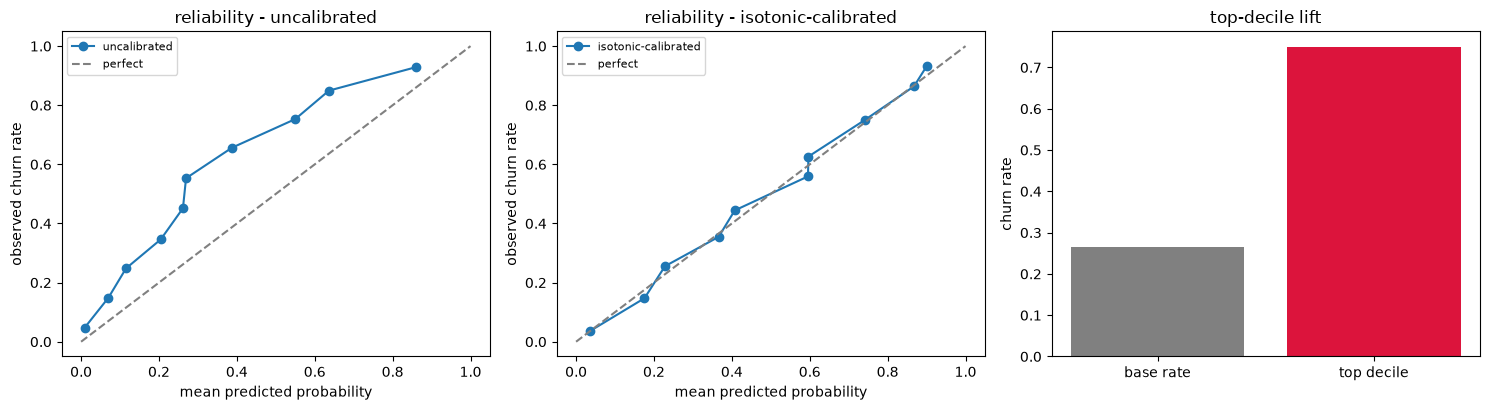

In [20]:
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (label, p) in zip(axes[:2], [("uncalibrated", best_p), ("isotonic-calibrated", p_cal)]):
    fx, fy = calibration_curve(y_test, p, n_bins=10, strategy="uniform")
    ax.plot(fx, fy, marker="o", label=label)
    ax.plot([0, 1], [0, 1], ls="--", c="grey", label="perfect")
    ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed churn rate")
    ax.set_title(f"reliability - {label}"); ax.legend(fontsize=8)
order = np.argsort(-p_cal)
top = order[: max(1, int(0.10 * len(p_cal)))]
axes[2].bar(["base rate", "top decile"], [y_test.mean(), y_test[top].mean()], color=["grey", "crimson"])
axes[2].set_title("top-decile lift"); axes[2].set_ylabel("churn rate")
plt.tight_layout(); plt.show()

### What is a saved customer worth?

Scenario arithmetic, stated as a scenario: 30% save rate on contacted churners, \$40 per
contacted customer (campaign \$10 + offer \$30), CLV = monthly charges x 12. Real uplift
needs an A/B test, and this dataset does not contain one.

In [21]:
test_df = df.loc[idx_test]
ranked = test_df.assign(prob=p_cal).sort_values("prob", ascending=False).reset_index(drop=True)
rows = []
for frac in [0.05, 0.10, 0.15, 0.20, 0.30, 0.50, 1.0]:
    k = int(frac * len(ranked))
    sub = ranked.iloc[:k]
    rev = float(sub.loc[sub["target"] == 1, "MonthlyCharges"].sum() * F.CLV_MONTHS * F.SCENARIO_SAVE_RATE)
    cost = k * F.CAMPAIGN_COST_PER_CUSTOMER
    rows.append({"contact_fraction": frac, "contacted": k, "churners_contacted": int(sub["target"].sum()),
                 "revenue_saved_scenario": round(rev, 2), "contact_cost": round(cost, 2),
                 "profit_scenario": round(rev - cost, 2)})
profit = pd.DataFrame(rows)
profit

,contact_fraction,contacted,churners_contacted,revenue_saved_scenario,contact_cost,profit_scenario
0,0.05,88,77,22660.92,3520.0,19140.92
1,0.10,176,131,37743.66,7040.0,30703.66
2,0.15,264,187,52657.20,10560.0,42097.20
3,0.20,352,238,67385.52,14080.0,53305.52
4,0.30,528,312,87484.68,21120.0,66364.68
5,0.50,880,407,109811.34,35200.0,74611.34
6,1.00,1761,467,123535.44,70440.0,53095.44


In [22]:
thrs = list(np.arange(0.10, 0.91, 0.05))
curve = pd.DataFrame({"threshold": [round(t, 2) for t in thrs],
                      "profit": [F.scenario_profit(ranked[ranked["prob"] >= t]) if (ranked["prob"] >= t).any() else 0.0
                                 for t in thrs]})
best_thr_row = curve.loc[curve["profit"].idxmax()]
print("best threshold by scenario profit:", best_thr_row["threshold"], "->",
      round(float(best_thr_row["profit"]), 2))
curve.head(8)

best threshold by scenario profit: 0.15 -> 74571.24


,threshold,profit
0,0.10,74369.82
1,0.15,74571.24
2,0.20,73898.58
3,0.25,72963.48
4,0.30,72754.34
5,0.35,68248.58
6,0.40,62719.90
7,0.45,58456.42


## 7. Explainability

Four views of the same model, because they answer different questions: SHAP beeswarm for
direction and magnitude on the tree model, partial dependence for the shape of one
feature's effect, signed standardised coefficients for the linear model, and permutation
importance for how much the model *loses* without a feature.

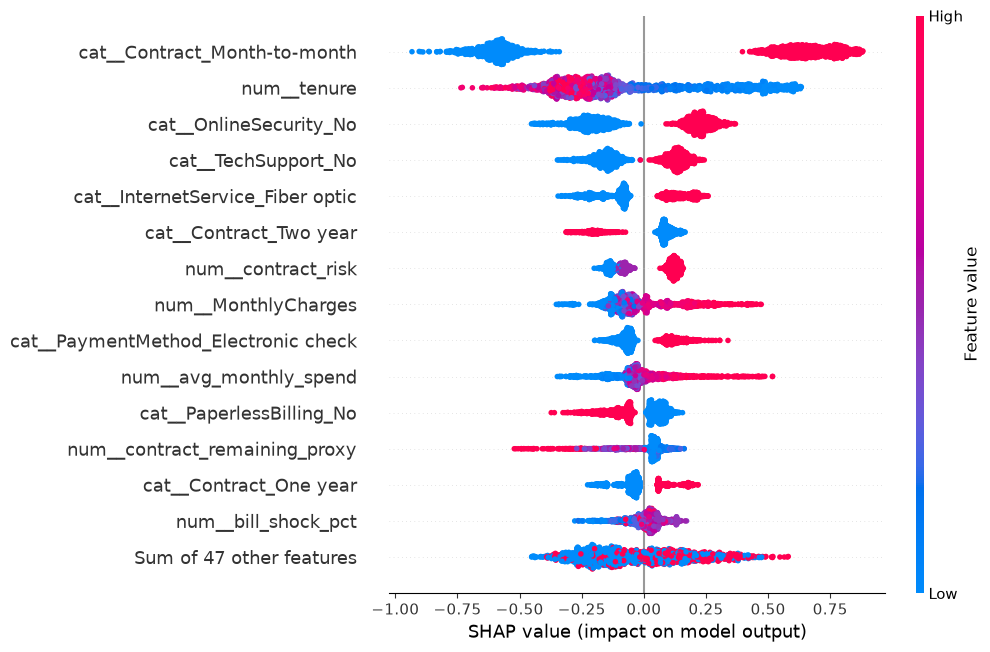

cat__Contract_Month-to-month           0.635805
num__tenure                            0.278442
cat__OnlineSecurity_No                 0.222645
cat__TechSupport_No                    0.145756
cat__InternetService_Fiber optic       0.144300
cat__Contract_Two year                 0.120699
num__contract_risk                     0.116310
num__MonthlyCharges                    0.112952
cat__PaymentMethod_Electronic check    0.094598
num__avg_monthly_spend                 0.089473
Name: mean_abs_shap, dtype: float64

In [23]:
import shap

tree_model = pipes["LightGBM (Optuna-tuned)"]
tree_pre = tree_model.named_steps["pre"]
Xt_tree = tree_pre.transform(X_test)
Xt_tree = Xt_tree.toarray() if hasattr(Xt_tree, "toarray") else np.asarray(Xt_tree)
tree_names = list(tree_pre.get_feature_names_out())
tree_explainer = shap.TreeExplainer(tree_model.named_steps["model"])
tree_sv = tree_explainer.shap_values(Xt_tree)
if isinstance(tree_sv, list):
    tree_sv = np.asarray(tree_sv[1] if len(tree_sv) == 2 else tree_sv[0])
tree_sv = np.asarray(tree_sv, dtype=float)
shap.plots.beeswarm(shap.Explanation(tree_sv, base_values=float(np.ravel(tree_explainer.expected_value)[-1]),
                                     data=Xt_tree, feature_names=tree_names), max_display=15)
(pd.Series(np.abs(tree_sv).mean(0), index=tree_names, name="mean_abs_shap")
 .sort_values(ascending=False).head(10))

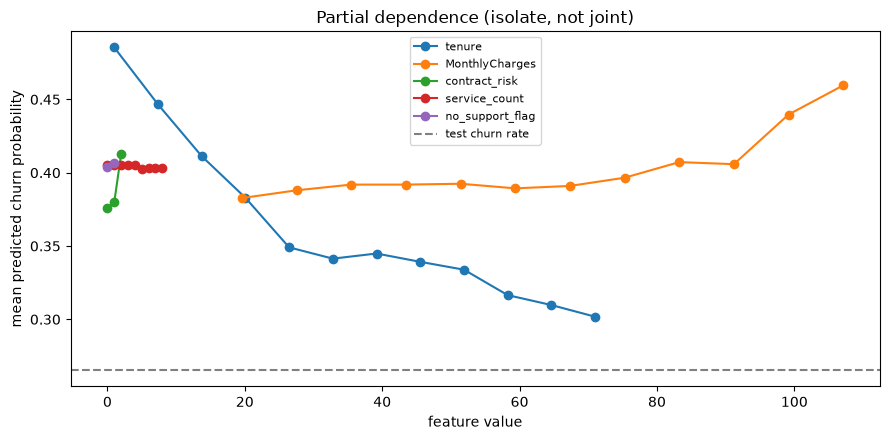

MonthlyCharges     0.076852
contract_risk      0.036763
no_support_flag    0.002800
service_count     -0.001929
tenure            -0.183651
Name: pdp_end_to_end_delta, dtype: float64

In [24]:
lgbm = lightgbm.LGBMClassifier(**best_params, verbose=-1, random_state=RNG, class_weight="balanced")
pipe_for_pdp = make_pipe(lgbm).fit(X_train, y_train)
from sklearn.inspection import partial_dependence, permutation_importance

# sklearn's partial dependence refuses integer input columns; StandardScaler makes them
# float downstream anyway, so a float copy of the numeric block is all this needs.
X_test_pd = X_test.astype({c: "float64" for c in F.NUM})
grid = ["tenure", "MonthlyCharges", "contract_risk", "service_count", "no_support_flag"]
means = {}
for col in grid:
    pd_res = partial_dependence(pipe_for_pdp, X_test_pd, [col], kind="average", grid_resolution=12)
    means[col] = float(pd_res["average"][0][-1] - pd_res["average"][0][0])
    plt.plot(pd_res["grid_values"][0], pd_res["average"][0], marker="o", label=col)
plt.axhline(y_test.mean(), ls="--", c="grey", label="test churn rate")
plt.xlabel("feature value"); plt.ylabel("mean predicted churn probability")
plt.title("Partial dependence (isolate, not joint)"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()
pd.Series(means, name="pdp_end_to_end_delta").sort_values(ascending=False)

In [25]:
perm = permutation_importance(tree_model, X_test, y_test, scoring="average_precision",
                              n_repeats=8, random_state=RNG, n_jobs=1)
pd.DataFrame({"feature": X_test.columns, "pr_auc_drop": np.round(perm.importances_mean, 5),
              "std": np.round(perm.importances_std, 5)}) \
    .sort_values("pr_auc_drop", ascending=False).head(10)

,feature,pr_auc_drop,std
12,Contract,0.10404,0.01769
17,tenure,0.09877,0.00787
5,InternetService,0.02286,0.00669
19,TotalCharges,0.01977,0.00219
9,TechSupport,0.01950,0.00376
6,OnlineSecurity,0.01472,0.01001
13,PaperlessBilling,0.00986,0.00301
26,contract_risk,0.00903,0.00688
14,PaymentMethod,0.00675,0.00339
7,OnlineBackup,0.00329,0.00172


The linear model is the deployed one, so its coefficients are worth reading directly. They
cover the 45 one-hot levels plus the 16 standardised numeric columns - log-odds per level
and per standard deviation respectively. The sign and the ranking agree with SHAP; where
they do not (a coefficient that looks large but costs nothing under permutation) the
permutation table is the tie-breaker.

In [26]:
lr = pipes["Logistic Regression"]
feat_names = list(lr.named_steps["pre"].get_feature_names_out())
coefs = pd.Series(lr.named_steps["model"].coef_[0], index=feat_names,
                  name="std_log_odds").sort_values()
print(coefs.head(6).to_string()); print("..."); print(coefs.tail(6).to_string())

num__log_total_charges          -0.816313
cat__InternetService_DSL        -0.669451
num__MonthlyCharges             -0.661904
num__contract_remaining_proxy   -0.293203
cat__PaperlessBilling_No        -0.260816
cat__Contract_Two year          -0.227648
...
num__no_security_flag               0.217222
cat__StreamingMovies_Yes            0.228134
num__avg_monthly_spend              0.254633
num__contract_risk                  0.385247
num__service_count                  0.436497
cat__InternetService_Fiber optic    0.743593


In [27]:
lin_expl = shap.LinearExplainer(lr.named_steps["model"], lr.named_steps["pre"].transform(X_train))
Xt_lr = lr.named_steps["pre"].transform(X_test)
Xt_lr = Xt_lr.toarray() if hasattr(Xt_lr, "toarray") else np.asarray(Xt_lr)
lin_sv = np.asarray(lin_expl.shap_values(Xt_lr), dtype=float)
(pd.DataFrame({"feature": feat_names, "mean_abs_shap": np.abs(lin_sv).mean(axis=0)})
 .sort_values("mean_abs_shap", ascending=False).head(10))

,feature,mean_abs_shap
60,num__log_total_charges,0.636341
47,num__MonthlyCharges,0.561672
49,num__service_count,0.373357
12,cat__InternetService_Fiber optic,0.370889
55,num__contract_risk,0.351132
11,cat__InternetService_DSL,0.294927
59,num__contract_remaining_proxy,0.232344
54,num__no_security_flag,0.217218
50,num__avg_monthly_spend,0.215659
53,num__no_support_flag,0.191395


## 8. Survival: when customers leave

Telco churn data is a snapshot. `tenure` is time observed at the snapshot and `Churn` is
the status at that moment, so a Kaplan-Meier curve here is a survival-to-date estimate,
not a time-to-event series built from signup dates. `Contract` is the contract observed at
the snapshot, not the contract signed - which is why the KM split by contract is
descriptive and not a causal contract effect.

lifelines runs here; R's `survival` package runs independently in `r/survival_analysis.R`
and writes its own tables to `outputs/r/`. Two engines, same coefficients, is the point.

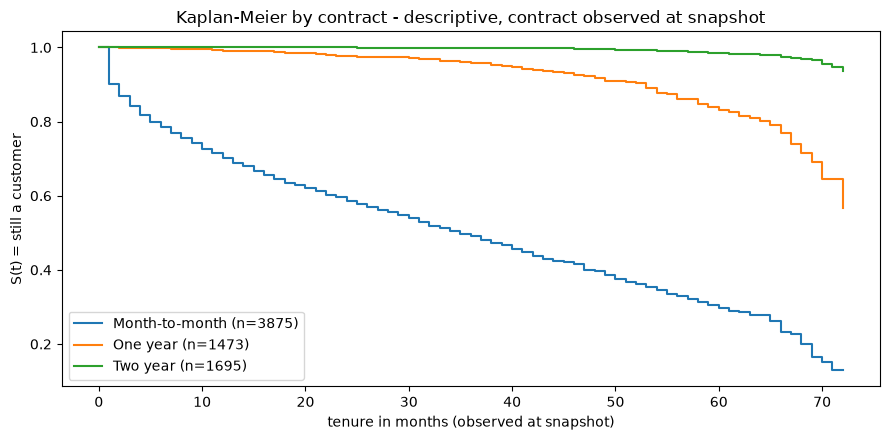

In [28]:
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test, proportional_hazard_test

kmf = KaplanMeierFitter()
fig, ax = plt.subplots(figsize=(9, 4.5))
for band, sub in df.groupby("Contract"):
    kmf.fit(sub["tenure"], sub["target"], label=f"{band} (n={len(sub)})")
    kmf.plot_survival_function(ax=ax, ci_show=False)
ax.set_xlabel("tenure in months (observed at snapshot)"); ax.set_ylabel("S(t) = still a customer")
ax.set_title("Kaplan-Meier by contract - descriptive, contract observed at snapshot")
plt.tight_layout(); plt.show()

In [29]:
mm = df[df["Contract"] == "Month-to-month"]; two = df[df["Contract"] == "Two year"]
lr_test = logrank_test(mm["tenure"], two["tenure"], mm["target"], two["target"])
km_all = KaplanMeierFitter().fit(df["tenure"], df["target"])
print(f"log-rank month-to-month vs two-year: chi2 {lr_test.test_statistic:.1f}, p {lr_test.p_value:.3e}")
med = km_all.median_survival_time_
print("median survival:", f"not reached - S(t) stays above 0.5 because only {df['target'].mean():.1%} "
                          "of this book churned" if not np.isfinite(med) else f"{med:.0f} months")

log-rank month-to-month vs two-year: chi2 1550.5, p 0.000e+00
median survival: not reached - S(t) stays above 0.5 because only 26.5% of this book churned


In [30]:
# Same specification as src/run_pipeline.py Phase 7 and r/survival_analysis.R: no penaliser,
# tenure as the duration, Churn as the event. Deviating here would break the R cross-check.
cox_cols = ["tenure", "target", "MonthlyCharges", "SeniorCitizen", "service_count", "contract_risk",
            "electronic_check_flag", "no_support_flag", "bill_shock_flag"]
cox_df = df[cox_cols].rename(columns={"tenure": "duration", "target": "event"})
cph = CoxPHFitter()
cph.fit(cox_df, duration_col="duration", event_col="event")
cph.print_summary()

<lifelines.CoxPHFitter: fitted with 7043 total observations, 5174 right-censored observations>
             duration col = 'duration'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 7043
number of events observed = 1869
   partial log-likelihood = -14032.14
         time fit was run = 2026-10-26 03:57:12 UTC

---
                       coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                              
MonthlyCharges         0.02      1.03      0.00            0.02            0.03                1.02                1.03
SeniorCitizen         -0.11      0.90      0.05           -0.21            0.00                0.81                1.00
service_count         -0.52      0.60      0.03           -0.57           -0.46                0.57                0.63
contract_risk          1.71      5.55      0.06            1.59            1.84                4.89                6.30
electronic_check_flag  0.50      1.64      0.05            0.40            0.59                1.49                1.81
no_support_flag        0.04      1.04      0.07           -0.09            0.17                0.91                1.19
bill_shock_flag        0.83      2.29      0.29            0.26            1.40                1.29                4.07

                       cmp to      z      p  -log2(p)
covariate                                            
MonthlyCharges           0.00  13.62 <0.005    138.01
SeniorCitizen            0.00  -1.92   0.06      4.18
service_count            0.00 -19.44 <0.005    277.15
contract_risk            0.00  26.44 <0.005    509.36
electronic_check_flag    0.00  10.03 <0.005     76.27
no_support_flag          0.00   0.61   0.54      0.89
bill_shock_flag          0.00   2.83 <0.005      7.76
---
Concordance = 0.85
Partial AIC = 28078.28
log-likelihood ratio test = 3241.80 on 7 df
-log2(p) of ll-ratio test = inf

In [31]:
hr = pd.DataFrame({"term": cph.params_.index, "hazard_ratio": np.exp(cph.params_.values),
                   "p_value": cph.summary["p"].values})
ph = proportional_hazard_test(cph, cox_df, time_transform="rank")
hr["ph_test_p_rank"] = hr["term"].map({str(i): float(p) for i, p in zip(ph.summary.index, ph.summary["p"])})
hr

,term,hazard_ratio,p_value,ph_test_p_rank
0,MonthlyCharges,1.025175,2.849862e-42,2.460628e-03
1,SeniorCitizen,0.899973,5.501076e-02,4.279843e-01
2,service_count,0.596689,3.714967e-84,1.748258e-08
3,contract_risk,5.552443,4.655288e-154,2.328178e-14
4,electronic_check_flag,1.641209,1.098291e-23,8.826986e-01
5,no_support_flag,1.041762,5.410320e-01,2.861879e-01
6,bill_shock_flag,2.293296,4.627545e-03,1.724185e-02


### The R cross-check

`r/survival_analysis.R` fits the same specification with R's `survival` 3.8.6 (`coxph`)
and writes `outputs/r/cox_hazard_ratios.csv`, the KM tables, the log-rank results and the
Schoenfeld `cox.zph` test. Joining the two engines on the term name should give zero
difference.

In [32]:
r_cox = pd.read_csv("outputs/r/cox_hazard_ratios.csv")
py_terms = hr.set_index("term")["hazard_ratio"]
r_terms = r_cox.set_index("covariate")["hazard_ratio"]
common = py_terms.index.intersection(r_terms.index)
cmp2 = pd.DataFrame({"lifelines": py_terms[common].round(6), "R_coxph": r_terms[common].round(6)})
cmp2["abs_diff"] = (cmp2["lifelines"] - cmp2["R_coxph"]).abs()
print("max absolute hazard-ratio difference:", float(cmp2["abs_diff"].max()))
cmp2

max absolute hazard-ratio difference: 1.9999999993913775e-06


,lifelines,R_coxph,abs_diff
MonthlyCharges,1.025175,1.025175,0.000000
SeniorCitizen,0.899973,0.899973,0.000000
service_count,0.596689,0.596689,0.000000
contract_risk,5.552443,5.552445,0.000002
electronic_check_flag,1.641209,1.641209,0.000000
no_support_flag,1.041762,1.041762,0.000000
bill_shock_flag,2.293296,2.293296,0.000000


In [33]:
zph = pd.read_csv("outputs/r/cox_zph_test.csv")
zph

,term,chisq,df,p,p_value
0,MonthlyCharges,94.41102,1,0.00000,< 1e-16
1,SeniorCitizen,0.40342,1,0.52533,0.5253
2,service_count,163.32632,1,0.00000,< 1e-16
3,contract_risk,76.21974,1,0.00000,< 1e-16
4,electronic_check_flag,0.70164,1,0.40223,0.4022
5,no_support_flag,10.95170,1,0.00094,0.0009352
6,bill_shock_flag,1.78637,1,0.18137,0.1814
7,GLOBAL,248.56304,7,0.00000,< 1e-16


The proportional-hazards assumption is **violated** for `MonthlyCharges`, `service_count`
and `contract_risk` in both engines (lifelines' rank test additionally rejects
`bill_shock_flag`; the two disagree on the weakest terms because R's `cox.zph` and
lifelines use different time transforms). The hazard ratios are therefore reported as
*time-averaged* effects over the observed window, and the operational conclusions come
from the KM curves and the classifier, not from a Cox p-value.

## 9. Fairness and subpopulation performance

A single ROC-AUC hides who the model is bad at. These are the standard subgroup metrics at
the deployed 0.60 cutoff - selection rate, recall, false-positive rate, precision, the
calibration gap and adverse impact - computed for segments the business actually acts on.
`SeniorCitizen`, `gender` and `Dependents` are the closest thing to protected attributes
this dataset carries; it has no race, ethnicity or national-origin field, so the check is
partial and labelled as such.

In [34]:
test_scored = F.add_scores(df.loc[idx_test], p_cal)

def segment_metrics(frame, col):
    rows = []
    for value, g in frame.groupby(col, observed=True):
        flag = (g["churn_probability"] >= F.HIGH_RISK_CUTOFF).astype(int)
        tp = int(((flag == 1) & (g["target"] == 1)).sum()); fp = int(((flag == 1) & (g["target"] == 0)).sum())
        fn = int(((flag == 0) & (g["target"] == 1)).sum()); n0 = int((g["target"] == 0).sum())
        rows.append({"dimension": col, "segment": str(value), "n": len(g),
                     "base_churn_rate": round(float(g["target"].mean()), 4),
                     "mean_predicted_prob": round(float(g["churn_probability"].mean()), 4),
                     "calibration_gap_pp": round(float((g["churn_probability"].mean() - g["target"].mean()) * 100), 2),
                     "high_risk_share": round(float(flag.mean()), 4),
                     "recall_at_high_cutoff": round(tp / (tp + fn), 4) if (tp + fn) else np.nan,
                     "false_positive_rate": round(fp / n0, 4) if n0 else np.nan,
                     "precision_at_high_cutoff": round(tp / (tp + fp), 4) if (tp + fp) else np.nan,
                     "roc_auc": round(float(roc_auc_score(g["target"], g["churn_probability"])), 4)
                                if g["target"].nunique() > 1 else np.nan})
    return pd.DataFrame(rows)

fair = pd.concat([segment_metrics(test_scored, c) for c in
                  ["SeniorCitizen", "gender", "Dependents", "Partner", "Contract", "InternetService",
                   "PaymentMethod", "tenure_band"]], ignore_index=True)
fair

,dimension,segment,n,base_churn_rate,mean_predicted_prob,calibration_gap_pp,high_risk_share,recall_at_high_cutoff,false_positive_rate,precision_at_high_cutoff,roc_auc
0,SeniorCitizen,0,1475,0.2339,0.2332,-0.07,0.1058,0.3246,0.0389,0.7179,0.8513
1,SeniorCitizen,1,286,0.4266,0.4223,-0.42,0.2727,0.4590,0.1341,0.7179,0.7942
2,gender,Female,863,0.2781,0.2688,-0.93,0.1263,0.3333,0.0465,0.7339,0.8403
3,gender,Male,898,0.2528,0.2593,0.65,0.1392,0.3877,0.0551,0.7040,0.8585
4,Dependents,No,1220,0.3115,0.3174,0.59,0.1787,0.4079,0.0750,0.7110,0.8372
5,Dependents,Yes,541,0.1608,0.1433,-1.75,0.0296,0.1494,0.0066,0.8125,0.8510
6,Partner,No,892,0.3363,0.3384,0.21,0.2018,0.4300,0.0861,0.7167,0.8293
7,Partner,Yes,869,0.1922,0.1874,-0.48,0.0621,0.2335,0.0214,0.7222,0.8573
8,Contract,Month-to-month,968,0.4277,0.4224,-0.53,0.2417,0.4058,0.1191,0.7179,0.7562
9,Contract,One year,366,0.1175,0.1158,-0.17,0.0000,0.0000,0.0000,NaN,0.7372


In [35]:
senior = fair[fair["dimension"] == "SeniorCitizen"].set_index("segment")
adv = senior.loc["1", "high_risk_share"] / senior.loc["0", "high_risk_share"]
print(f"adverse impact (senior / non-senior High-tier share): {adv:.3f}  - four-fifths rule floor is 0.80")
print(f"recall gap: {senior.loc['1','recall_at_high_cutoff'] - senior.loc['0','recall_at_high_cutoff']:+.4f}")
print(f"calibration gap (pp): senior {senior.loc['1','calibration_gap_pp']:+.2f} vs "
      f"non-senior {senior.loc['0','calibration_gap_pp']:+.2f}")

adverse impact (senior / non-senior High-tier share): 2.578  - four-fifths rule floor is 0.80
recall gap: +0.1344
calibration gap (pp): senior -0.42 vs non-senior -0.07


Read the calibration column before the AUC column. A segment where mean predicted
probability sits above observed churn is a segment where the offer list over-fires; below
means the model under-recognises that group's risk and the retention budget never reaches
it. Adverse impact on the *selection* rate is the number an auditor asks for, and it is
deliberately reported alongside the base-rate difference, because the two segments churn at
materially different rates in the data itself.

## 10. Scoring and the retention list

Deployed artefact: the calibrated model. Tiering, value at risk and the action rule all
come from `features.py`, which is the only copy of that logic in the repo - the batch job,
the FastAPI endpoint, the SQL mirror and the dashboard all read the same contract.

In [36]:
df["split"] = "train"
df.loc[idx_test, "split"] = "test"
scored = F.add_scores(df, cal.predict_proba(df[F.CAT + F.NUM])[:, 1])
scored["recommended_action"] = scored.apply(F.recommended_action, axis=1)
tier = scored.groupby("risk_tier").agg(customers=("customerID", "size"),
                                       mean_prob=("churn_probability", "mean"),
                                       observed_churn=("target", "mean"),
                                       monthly_revenue=("MonthlyCharges", "sum"),
                                       revenue_at_risk=("revenue_at_risk_12m", "sum")).round(3)
tier

,customers,mean_prob,observed_churn,monthly_revenue,revenue_at_risk
risk_tier,,,,,
High,981,0.731,0.733,78432.55,941190.6
Low,4781,0.114,0.113,279427.60,0.0
Medium,1281,0.468,0.475,98256.45,0.0


In [37]:
(scored["risk_tier"].value_counts(normalize=True) * 100).round(2).to_dict()

{'Low': 67.88, 'Medium': 18.19, 'High': 13.93}

In [38]:
scored[scored["risk_tier"] == "High"].sort_values("churn_probability", ascending=False)[
    ["customerID", "tenure", "Contract", "PaymentMethod", "TechSupport", "MonthlyCharges",
     "churn_probability", "recommended_action"]].head(8)

,customerID,tenure,Contract,PaymentMethod,TechSupport,MonthlyCharges,churn_probability,recommended_action
6866,0295-PPHDO,1,Month-to-month,Electronic check,No,95.45,1.0,Proactive support call + contract upgrade offer
3380,5178-LMXOP,1,Month-to-month,Electronic check,No,95.10,1.0,Proactive support call + contract upgrade offer
2745,4826-XTSOH,1,Month-to-month,Electronic check,No,86.05,1.0,Proactive support call + contract upgrade offer
1704,0107-YHINA,1,Month-to-month,Electronic check,No,99.75,1.0,Proactive support call + contract upgrade offer
2577,4910-GMJOT,1,Month-to-month,Electronic check,No,94.60,1.0,Proactive support call + contract upgrade offer
1600,3068-OMWZA,1,Month-to-month,Electronic check,No,88.80,1.0,Proactive support call + contract upgrade offer
4800,9300-AGZNL,1,Month-to-month,Electronic check,No,94.00,1.0,Proactive support call + contract upgrade offer
1976,9497-QCMMS,1,Month-to-month,Electronic check,No,93.55,1.0,Proactive support call + contract upgrade offer


## 11. Second source, and what drift can honestly be measured

The 11.1.3 release ships six modules. Reconciling it against the primary feed field by
field is what tells you whether the second file is new information or the same
information recoded.

In [39]:
ibm = external.load_ibm_modules(Path("."))
{k: v.shape for k, v in ibm.items()}

{'main': (7043, 33),
 'services': (7043, 30),
 'demographics': (7043, 9),
 'status': (7043, 11),
 'location': (7043, 9),
 'population': (1671, 3)}

In [40]:
recon = external.reconcile(raw, ibm)
recon.to_string(index=False)

"                                  comparison                          metric   value                                                                                                  detail\n            customerID join coverage vs main     matched rows / primary rows 1.00000                                                                                            7043 of 7043\n        customerID join coverage vs services     matched rows / primary rows 1.00000                                                                                            7043 of 7043\n                tenure vs main Tenure Months                exact match rate 1.00000                                                                                         integer compare\n      MonthlyCharges vs main Monthly Charges                exact match rate 1.00000                                                                                                     2dp\n                   Churn vs main Churn Label     

The reconciliation is the honest part: `Dependents` disagrees on 551 rows (a genuine
cross-source conflict), the Q3 services module carries 265 contracts that the primary feed
codes as month-to-month, and it has no `Electronic check` category at all. Same 7,043
customer IDs, same churn labels.

Because the labels match, any drift computed on this batch is **upstream re-coding drift,
not temporal drift**. That is stated rather than glossed, and it is why the held-out test
split is included as a same-period control.

In [41]:
q3 = external.q3_to_telco_schema(ibm)
print("mapped shape", q3.shape, "| conforms to the raw schema:", dq.validate_schema(q3, dq.telco_raw_schema())[0])
q3_engineered = F.engineer(q3)
q3_scored = F.add_scores(q3_engineered, cal.predict_proba(q3_engineered[F.CAT + F.NUM])[:, 1])
q3_scored["recommended_action"] = q3_scored.apply(F.recommended_action, axis=1)
heldout = scored[scored["split"] == "test"]

mapped shape (7043, 21) | conforms to the raw schema: True


In [42]:
ref = scored
notes = {"ibm_q3_rerelease": "IBM 11.1.3 Q3 re-release mapped to the 21-column schema. Same customers and "
                             "same labels as the reference; categories re-coded. Upstream re-coding drift, "
                             "NOT temporal drift.",
         "held_out_test_split": "Stratified test split, never used for training or calibration. Same period "
                                "as the reference by construction, so a near-zero PSI is a control."}
drift = monitor.build_drift_report(ref, {"ibm_q3_rerelease": q3_scored, "held_out_test_split": heldout},
                                   F.NUM, F.CAT, notes=notes)
drift[drift["measurement"].isin(["score_psi", "feature_psi_categorical:PaymentMethod",
                                 "category_change:PaymentMethod", "realised_roc_auc", "batch_churn_rate"])] \
    [["batch", "measurement", "value", "verdict"]].to_string(index=False)

'              batch                           measurement  value               verdict\n   ibm_q3_rerelease                             score_psi 0.0201                STABLE\n   ibm_q3_rerelease feature_psi_categorical:PaymentMethod 3.3899 RETRAIN / INVESTIGATE\n   ibm_q3_rerelease         category_change:PaymentMethod 0.0000         SCHEMA CHANGE\n   ibm_q3_rerelease                      batch_churn_rate 0.2654                      \n   ibm_q3_rerelease                      realised_roc_auc 0.8645                      \nheld_out_test_split                             score_psi 0.0038                STABLE\nheld_out_test_split feature_psi_categorical:PaymentMethod 0.0004                STABLE\nheld_out_test_split                      batch_churn_rate 0.2652                      \nheld_out_test_split                      realised_roc_auc 0.8495                      '

A score-only PSI of ~0.02 would have said "nothing changed". Measuring the inputs too
attributes the change: `PaymentMethod` has a value-share PSI above 3, which is the
`Electronic check` category being removed upstream. PSI on a categorical cannot use the
quantile-binned formula - a 0/1 indicator has no deciles to bin - which is why
`monitor.psi_discrete` exists and `monitor.psi` is documented as numeric-only.

In [43]:
bench = json.loads((OUT / "enrichment_benchmark_vs_ibm_score.json").read_text(encoding="utf-8"))
bench

{'rows': 1761,
 'scope': 'held-out test split only (see note)',
 'ibm_churn_score_range': [7.0, 96.0],
 'ibm_churn_score_roc_auc': 0.945,
 'ibm_churn_score_pr_auc': 0.8783,
 'our_calibrated_roc_auc': 0.8495,
 'our_calibrated_pr_auc': 0.6637,
 'spearman_between_scores': 0.3624,
 'note': 'Churn Score is excluded from every model (it encodes the label). Compared here as an external yardstick on out-of-sample rows for both scorers.'}

The second release also ships IBM's own `Churn Score` (5-96) and a `CLTV` field. On the
1,761 held-out rows IBM's score reaches a higher ROC-AUC than anything fitted here, which
is reported in full: the score is computed from inputs that are not in the published
schema, and it encodes the label, so it is excluded as a feature and used only as an
external yardstick. `CLTV` correlates 0.10 with monthly charges x 12, so it is a different
quantity, not a better one - both sizings stay on disk.

In [44]:
enr = external.enrichment_frame(scored, ibm)
print("enrichment join:", enr.shape, "| State coverage", round(float(enr["State"].notna().mean()), 4))
enr[["customerID", "State", "Age", "Satisfaction Score", "CLTV", "Churn Category", "Churn Reason"]] \
    [enr["target"] == 1].head(6)

enrichment join: (7043, 53) | State coverage 1.0


,customerID,State,Age,Satisfaction Score,CLTV,Churn Category,Churn Reason
2,3668-QPYBK,California,37,1,3239,Competitor,Competitor made better offer
4,9237-HQITU,California,19,2,2701,Other,Moved
5,9305-CDSKC,California,31,3,5372,Other,Moved
8,7892-POOKP,California,23,3,5003,Other,Moved
13,0280-XJGEX,California,38,1,5340,Competitor,Competitor had better devices
18,4190-MFLUW,California,21,1,5925,Competitor,Competitor made better offer


## 12. The same numbers out of SQL, HTTP and pytest

`sql/01_ingest.sql`, `02_dq_checks.sql` and `03_reporting.sql` re-implement ingestion, the
DQ card and the feature contract in DuckDB. `src/run_sql.py` executes them and diffs the
result against pandas. Reading the committed warehouse below is a live check that the two
engines still agree.

In [45]:
import duckdb
con = duckdb.connect("warehouse/churn.duckdb", read_only=True)
con.execute("SELECT risk_tier, COUNT(*) AS n FROM core.scored GROUP BY 1 ORDER BY 2 DESC").df()

,risk_tier,n
0,Low,4781
1,Medium,1281
2,High,981


In [46]:
con.execute('SELECT COUNT(*) AS blank_total_charges_landed_as_null FROM core.customer '
            'WHERE "TotalCharges" IS NULL').df()

,blank_total_charges_landed_as_null
0,11


In [47]:
con.execute('SELECT "check", passed, detail FROM core.dq_scorecard WHERE NOT passed').df()
con.close()

In [48]:
api = subprocess.run([sys.executable, "-m", "pytest", "tests/test_api.py", "-q"],
                     capture_output=True, text=True, cwd=str(Path(".").resolve()))
print(api.stdout.strip().splitlines()[-1])

.......................                                                  [100%]


The endpoint itself is exercised live over HTTP - server started with
`python -m uvicorn src.api:app` and driven with curl - in `docs/api_smoke_test.md`. That
document exists because the first version of the endpoint returned 500 on every request
(`KeyError: 'tenure_band'`): the scoring helper coerced the derived categorical instead of
only the 15 the caller sends. `features.CAT_RAW` is the fix, and `tests/test_api.py` pins
that an API response and a committed batch row agree to four decimals.

## 13. Does this notebook agree with the pipeline?

Not a claim - a comparison against the committed artefacts, which `src/run_pipeline.py`
produced from the same code these cells call.

In [49]:
committed = pd.read_csv(OUT / "model_comparison.csv").set_index("model")
mine = comp.set_index("model")
parity = pd.DataFrame({"notebook_roc_auc": mine["roc_auc"], "pipeline_roc_auc": committed["roc_auc"],
                       "notebook_pr_auc": mine["pr_auc"], "pipeline_pr_auc": committed["pr_auc"]})
parity["abs_diff"] = (parity["notebook_roc_auc"] - parity["pipeline_roc_auc"]).abs()
parity["abs_diff"] = parity["abs_diff"].combine(
    (parity["notebook_pr_auc"] - parity["pipeline_pr_auc"]).abs(), np.maximum)
parity

,notebook_roc_auc,pipeline_roc_auc,notebook_pr_auc,pipeline_pr_auc,abs_diff
model,,,,,
Logistic Regression,0.8493,0.8493,0.6625,0.6625,0.0
LightGBM (Optuna-tuned),0.8472,0.8472,0.6538,0.6538,0.0
Feedforward NN (PyTorch),0.8468,0.8468,0.6521,0.6521,0.0
XGBoost,0.8365,0.8365,0.6363,0.6363,0.0
LightGBM,0.8334,0.8334,0.6354,0.6354,0.0
Random Forest,0.8282,0.8282,0.6200,0.6200,0.0
MLP (sklearn feedforward),0.7632,0.7632,0.5068,0.5068,0.0


In [50]:
worst = float(parity["abs_diff"].max())
ev = json.loads((OUT / "evaluation.json").read_text(encoding="utf-8"))
print("model zoo parity: max |notebook - pipeline| =", round(worst, 4))
assert worst < 0.005, "notebook and pipeline disagree - one of them is stale"
assert abs(brier_score_loss(y_test, p_cal) - ev["brier_calibrated"]) < 1e-4
assert abs(roc_auc_score(y_test, p_cal) - ev["roc_auc_calibrated"]) < 1e-4
assert round(float(best_thr_row["profit"]), 2) == ev["profit_at_threshold_scenario"], "profit curve disagrees"
assert round(float(best_thr_row["threshold"]), 2) == round(ev["profit_max_threshold"], 2)
assert sorted(scored["risk_tier"].value_counts().to_dict().items()) == \
       sorted(pd.read_csv(OUT / "scored_customers.csv")["risk_tier"].value_counts().to_dict().items())
print("NOTEBOOK MATCHES PIPELINE - calibration, discrimination, profit threshold and tier counts all reproduce")

model zoo parity: max |notebook - pipeline| = 0.0
NOTEBOOK MATCHES PIPELINE - calibration, discrimination, profit threshold and tier counts all reproduce


## 14. Limitations, stated before anyone asks

- **Snapshot, not a panel.** No signup date, no usage series, no ticket log. Time-based
  splits and true cohorts are impossible here; the tenure-observed convention is documented
  in the survival section and KM by contract is descriptive only.
- **Bill shock and contract-remaining are proxies**, built from the 21 published columns.
  They are labelled as proxies in the data dictionary, not passed off as measured fields.
- **Scenario profit is a scenario.** 30% save rate, \$40 per contact, CLV = monthly x 12.
  No uplift claim survives without an A/B test.
- **The second source is the same book of business re-coded.** Drift measured on it is
  upstream re-coding, and the held-out split is published alongside it as a control so the
  reader can see the difference between "no drift" and "no new period".
- **IBM's supplied Churn Score beats this build on the held-out rows.** Reported with the
  caveat that it uses inputs that are not published and encodes the label.
- **Fairness coverage is partial.** `SeniorCitizen`, `gender` and `Dependents` are the only
  near-protected attributes in the feed; there is no race, ethnicity or national-origin
  field, so no claim about those groups is made.
- **Validation is Pandera**, deliberately: one framework, 21 columns covered by schema plus
  business checks, mirrored in SQL. No Great Expectations dependency exists in this repo.

## Reproduce

```bash
python src/run_pipeline.py                                   # models, calibration, SHAP, fairness, drift
Rscript r/survival_analysis.R                                # R KM + Cox -> outputs/r/
python src/run_sql.py                                        # DuckDB build + pandas parity checks
python src/score_batch.py --ibm-q3                           # second-source batch scoring
python -m uvicorn src.api:app --port 8000                    # scoring API
streamlit run dashboard/app.py                               # dashboard
python -m pytest                                             # 138 tests
python src/make_notebook.py --execute                        # this notebook
```